In [32]:
!pip install higher -q

import torch, os, higher
print('PyTorch :', torch.__version__)
print('higher  : installed OK')
print('CUDA    :', torch.cuda.is_available())
print('GPUs    :', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f'  GPU {i} :', torch.cuda.get_device_name(i))

PyTorch : 2.10.0+cu128
higher  : installed OK
CUDA    : True
GPUs    : 2
  GPU 0 : Tesla T4
  GPU 1 : Tesla T4


In [33]:
import torch, os

DATA_ROOT = '/kaggle/input/datasets/rayeneeeeeeeeee/nctcrche100k/9 Class Colon Cancer Histopathological Image'
OUT_DIR   = '/kaggle/working'
CKPT_PATH = os.path.join(OUT_DIR, 'maml_resnet_higher_best.pt')

N_WAY   = 5
K_SHOT  = 5
Q_QUERY = 10
META_BS = 2

INNER_STEPS = 5
INNER_LR    = 0.01
OUTER_LR    = 0.0001
NUM_EPOCHS  = 20
COPY_INITIAL_WEIGHTS = False

TRAIN_EPS = 400
VAL_EPS   = 100
TEST_EPS  = 100

IMG_SIZE = 128
DEVICE   = 'cuda' if torch.cuda.is_available() else 'cpu'

print('Device   :', DEVICE)
print('Data root:', os.path.isdir(DATA_ROOT))
print(f'IMG_SIZE : {IMG_SIZE}  META_BS : {META_BS}')

Device   : cuda
Data root: True
IMG_SIZE : 128  META_BS : 2


In [34]:
import os, random

assert os.path.isdir(DATA_ROOT), f'Not found: {DATA_ROOT}'

classes = sorted([
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d))
])
print(f'Found {len(classes)} classes:')

class_to_files = {}
for c in classes:
    folder = os.path.join(DATA_ROOT, c)
    files  = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(('.jpg','.jpeg','.png','.tif','.tiff'))
    ]
    class_to_files[c] = files
    print(f'  {c:45s}: {len(files):6,}')

print(f'\nTotal: {sum(len(v) for v in class_to_files.values()):,}')
assert len(classes) >= N_WAY, f'Need >= {N_WAY} classes'

Found 9 classes:
  1. Normal                                    :  8,763
  2. Tumor                                     : 14,317
  3. Stroma                                    : 10,446
  4. Lympho                                    : 11,557
  5. Complex                                   : 13,536
  6. Debris                                    : 11,512
  7. Mucosa                                    :  8,896
  8. Adipose                                   : 10,407
  9. Background                                : 10,566

Total: 100,000


In [35]:
random.seed(42)

all_cls = list(class_to_files.keys())
random.shuffle(all_cls)

n_tr = max(int(0.6 * len(all_cls)), N_WAY)
n_vl = max(int(0.2 * len(all_cls)), N_WAY)

if n_tr + n_vl + N_WAY <= len(all_cls):
    train_cls = all_cls[:n_tr]
    val_cls   = all_cls[n_tr : n_tr + n_vl]
    test_cls  = all_cls[n_tr + n_vl :]
    print('Class-disjoint split')
    train_dict = {c: class_to_files[c] for c in train_cls}
    val_dict   = {c: class_to_files[c] for c in val_cls}
    test_dict  = {c: class_to_files[c] for c in test_cls}
else:
    print('Image-level split (not enough classes for disjoint)')
    def make_img_dict(fs, fe):
        d = {}
        for c, files in class_to_files.items():
            f = files[:]; random.shuffle(f)
            d[c] = f[int(fs*len(f)) : int(fe*len(f))]
        return d
    train_dict = make_img_dict(0.00, 0.70)
    val_dict   = make_img_dict(0.70, 0.85)
    test_dict  = make_img_dict(0.85, 1.00)

for name, d in [('Train', train_dict), ('Val', val_dict), ('Test', test_dict)]:
    total = sum(len(v) for v in d.values())
    print(f'{name:5s}: {len(d)} classes, {total:,} images')

Image-level split (not enough classes for disjoint)
Train: 9 classes, 69,996 images
Val  : 9 classes, 15,000 images
Test : 9 classes, 15,004 images


In [ ]:
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T


class FSLDataset(Dataset):
    def __init__(self, class_dict, n_way, k_shot, q_query,
                 n_episodes, img_size=128, augment=False):
        super().__init__()
        self.class_dict = class_dict
        self.classes    = list(class_dict.keys())
        self.n_way      = n_way
        self.k_shot     = k_shot
        self.q_query    = q_query
        self.n_episodes = n_episodes

        need  = k_shot + q_query
        short = [c for c, f in class_dict.items() if len(f) < need]
        assert not short, f'Too few images: {short}'

        aug = [
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.ColorJitter(0.2, 0.2, 0.2, 0.05),
        ] if augment else []

        self.transform = T.Compose(aug + [
            T.Resize([img_size, img_size]),
            T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406],
                        [0.229, 0.224, 0.225]),
        ])

    def __len__(self): return self.n_episodes

    def _load(self, path):
        return self.transform(Image.open(path).convert('RGB'))

    def __getitem__(self, _):
        chosen = random.sample(self.classes, self.n_way)
        sup_imgs, qry_imgs = [], []
        sup_tgts, qry_tgts = [], []
        for label, cls in enumerate(chosen):
            paths = random.sample(
                self.class_dict[cls],
                self.k_shot + self.q_query)
            for p in paths[:self.k_shot]:
                sup_imgs.append(self._load(p))
                sup_tgts.append(label)
            for p in paths[self.k_shot:]:
                qry_imgs.append(self._load(p))
                qry_tgts.append(label)
        return (torch.stack(sup_imgs),
                torch.stack(qry_imgs),
                torch.LongTensor(sup_tgts),
                torch.LongTensor(qry_tgts))


def collate_episodes(batch): return batch

train_ds = FSLDataset(train_dict, N_WAY, K_SHOT, Q_QUERY,
                      TRAIN_EPS, IMG_SIZE, augment=True)
val_ds   = FSLDataset(val_dict,   N_WAY, K_SHOT, Q_QUERY,
                      VAL_EPS,   IMG_SIZE)
test_ds  = FSLDataset(test_dict,  N_WAY, K_SHOT, Q_QUERY,
                      TEST_EPS,  IMG_SIZE)

train_dl = DataLoader(train_ds, META_BS, shuffle=True,
                      num_workers=2, collate_fn=collate_episodes)
val_dl   = DataLoader(val_ds,   META_BS, shuffle=False,
                      num_workers=2, collate_fn=collate_episodes)
test_dl  = DataLoader(test_ds,  META_BS, shuffle=False,
                      num_workers=2, collate_fn=collate_episodes)

print(f'Train : {len(train_dl)} batches  ({TRAIN_EPS} episodes)')
print(f'Val   : {len(val_dl)} batches  ({VAL_EPS} episodes)')
print(f'Test  : {len(test_dl)} batches  ({TEST_EPS} episodes)')


In [ ]:
import torch.nn as nn
import torchvision.models as models


class MAML(nn.Module):
    def __init__(self, n_way):
        super().__init__()
        backbone = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT)

        self.frozen = nn.Sequential(
            backbone.conv1, backbone.bn1,
            backbone.relu, backbone.maxpool,
            backbone.layer1, backbone.layer2,
            backbone.layer3,
        )
        for p in self.frozen.parameters():
            p.requires_grad = False

        self.meta_layer = backbone.layer4
        self.avgpool    = backbone.avgpool
        self.classifier = nn.Linear(512, n_way)
        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, x):
        with torch.no_grad():
            x = self.frozen(x)
        x = self.meta_layer(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


model = MAML(N_WAY).to(DEVICE)

frozen_p    = sum(p.numel() for p in model.frozen.parameters())
trainable_p = sum(p.numel() for p in model.parameters()
                  if p.requires_grad)
print(f'Frozen params    : {frozen_p:,}')
print(f'Trainable params : {trainable_p:,}')

dummy  = torch.zeros(4, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
logits = model(dummy)
print(f'Output shape     : {tuple(logits.shape)}')


In [ ]:
import time, gc


def accuracy(logits, targets):
    return (logits.argmax(1) == targets
            ).float().mean().item() * 100


def run_epoch(model, loader, optimizer=None, phase='train'):
    ce       = nn.CrossEntropyLoss()
    is_train = (phase == 'train')
    all_acc, all_loss = [], []

    model.train() if is_train else model.eval()

    for batch in loader:
        if is_train:
            optimizer.zero_grad(set_to_none=True)

        meta_loss = torch.tensor(0.0, device=DEVICE)
        batch_acc = []

        for (support, query, s_tgt, q_tgt) in batch:
            support = support.to(DEVICE)
            query   = query.to(DEVICE)
            s_tgt   = s_tgt.to(DEVICE)
            q_tgt   = q_tgt.to(DEVICE)

            inner_opt = torch.optim.SGD(
                model.parameters(), lr=INNER_LR)

            # inner loop: adapt a functional copy on the support set;
            # gradients are tracked through it only when training
            with higher.innerloop_ctx(
                model, inner_opt,
                copy_initial_weights=COPY_INITIAL_WEIGHTS,
                track_higher_grads=is_train,
            ) as (fmodel, diffopt):
                for _ in range(INNER_STEPS):
                    s_loss = ce(fmodel(support), s_tgt)
                    diffopt.step(s_loss)
                q_logits   = fmodel(query)
                outer_loss = ce(q_logits, q_tgt)

            if not is_train:
                outer_loss = outer_loss.detach()
            meta_loss = meta_loss + outer_loss
            batch_acc.append(
                accuracy(q_logits.detach().cpu(),
                         q_tgt.cpu()))

        meta_loss = meta_loss / len(batch)
        if is_train:
            # outer loop: backprop the query loss to the meta-parameters
            meta_loss.backward()
            nn.utils.clip_grad_norm_(
                model.parameters(), 10.0)
            optimizer.step()

        all_loss.append(meta_loss.item())
        all_acc.extend(batch_acc)

    return (sum(all_acc) / len(all_acc),
            sum(all_loss) / len(all_loss))


optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad,
           model.parameters()), lr=OUTER_LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS)

best_val_acc = 0.0
history = {
    'train_acc': [], 'val_acc': [],
    'train_loss': [], 'val_loss': [],
}

print(f'Training {NUM_EPOCHS} epochs')
print(f'{TRAIN_EPS} train / {VAL_EPS} val episodes per epoch')
print(f'Inner : {INNER_STEPS} SGD steps @ lr={INNER_LR}')
print(f'Outer : Adam lr={OUTER_LR} | CosineAnnealing')
print('-' * 72)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    tr_acc, tr_loss = run_epoch(model, train_dl, optimizer, 'train')
    vl_acc, vl_loss = run_epoch(model, val_dl, phase='eval')
    scheduler.step()

    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)

    print(f'Epoch {epoch:02d}/{NUM_EPOCHS}  '
          f'Train {tr_acc:5.1f}% loss={tr_loss:.4f}  '
          f'Val {vl_acc:5.1f}% loss={vl_loss:.4f}  '
          f'({time.time()-t0:.0f}s)')

    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save(model.state_dict(), CKPT_PATH)
        print(f'  -> Best val acc: {best_val_acc:.2f}%  [saved]')

    torch.cuda.empty_cache()
    gc.collect()

print('-' * 72)
print(f'Done. Best val acc: {best_val_acc:.2f}%')

Training 20 epochs
400 train / 100 val episodes per epoch
Inner : 5 SGD steps @ lr=0.01
Outer : Adam lr=0.0001 | CosineAnnealing
FOMAML: True
------------------------------------------------------------------------
Epoch 01/20  Train  72.2% loss=0.7820  Val  84.9% loss=0.4805  (306s)
  -> Best val acc: 84.86%  [saved]
Epoch 02/20  Train  89.7% loss=0.3252  Val  86.9% loss=0.4085  (275s)
  -> Best val acc: 86.86%  [saved]
Epoch 03/20  Train  93.4% loss=0.2051  Val  86.5% loss=0.4109  (215s)
Epoch 04/20  Train  94.6% loss=0.1663  Val  85.8% loss=0.4378  (189s)
Epoch 05/20  Train  95.5% loss=0.1352  Val  86.4% loss=0.4225  (178s)
Epoch 06/20  Train  96.3% loss=0.1122  Val  86.3% loss=0.4265  (168s)
Epoch 07/20  Train  96.6% loss=0.1052  Val  86.6% loss=0.4231  (163s)
Epoch 08/20  Train  96.9% loss=0.1001  Val  84.8% loss=0.4593  (159s)
Epoch 09/20  Train  96.9% loss=0.0970  Val  86.4% loss=0.4244  (157s)
Epoch 10/20  Train  97.1% loss=0.0913  Val  85.4% loss=0.4530  (156s)
Epoch 11/20  Tr

In [41]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
test_acc, test_loss = run_epoch(model, test_dl, phase='eval')

baseline = 100.0 / N_WAY
print(f'Random baseline : {baseline:.1f}%')
print(f'Test accuracy   : {test_acc:.2f}%')
print(f'Test loss       : {test_loss:.4f}')
print(f'Gain over random: +{test_acc - baseline:.1f}%')

Random baseline : 20.0%
Test accuracy   : 87.28%
Test loss       : 0.4279
Gain over random: +67.3%


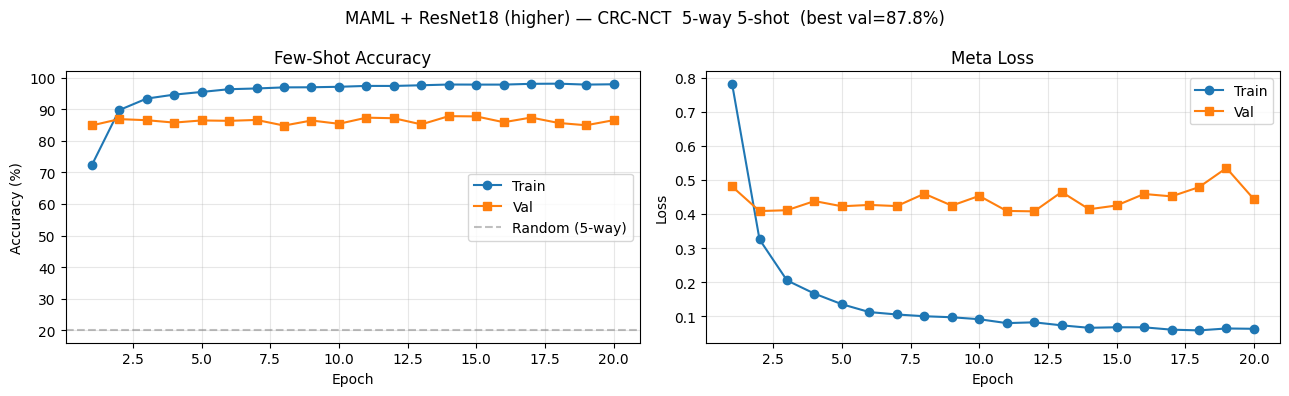

Saved to /kaggle/working


In [42]:
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_acc']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs, history['train_acc'], 'o-', label='Train')
ax1.plot(epochs, history['val_acc'],   's-', label='Val')
ax1.axhline(100/N_WAY, color='gray', linestyle='--',
            alpha=0.5, label=f'Random ({N_WAY}-way)')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy (%)')
ax1.set_title('Few-Shot Accuracy')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, history['train_loss'], 'o-', label='Train')
ax2.plot(epochs, history['val_loss'],   's-', label='Val')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.set_title('Meta Loss')
ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle(
    f'MAML + ResNet18 (higher) — CRC-NCT  '
    f'{N_WAY}-way {K_SHOT}-shot  '
    f'(best val={best_val_acc:.1f}%)',
    fontsize=12
)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'maml_higher_curves.png'), dpi=150)
plt.show()
print('Saved to', OUT_DIR)

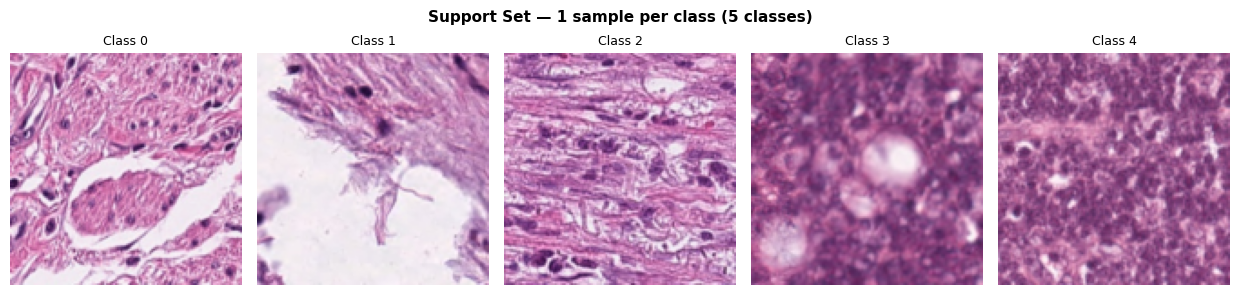

Support set saved.


In [43]:
import matplotlib.pyplot as plt
import numpy as np

MEAN_T = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
STD_T  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
denorm = lambda t: (t * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

support, query, s_tgt, q_tgt = val_ds[0]
support = support.to(DEVICE)
query   = query.to(DEVICE)
s_tgt   = s_tgt.to(DEVICE)
q_tgt   = q_tgt.to(DEVICE)

inner_opt = torch.optim.SGD(model.parameters(), lr=INNER_LR)
ce        = nn.CrossEntropyLoss()

with higher.innerloop_ctx(
    model, inner_opt,
    copy_initial_weights=COPY_INITIAL_WEIGHTS,
    track_higher_grads=False,
) as (fmodel, diffopt):
    for _ in range(INNER_STEPS):
        inner_loss = ce(fmodel(support), s_tgt)
        diffopt.step(inner_loss)
    with torch.no_grad():
        q_logits = fmodel(query)
        q_preds  = q_logits.argmax(1)

fig, axes = plt.subplots(1, N_WAY, figsize=(N_WAY * 2.5, 3))
for cls_idx in range(N_WAY):
    img_idx = (s_tgt == cls_idx).nonzero(as_tuple=True)[0][0].item()
    img     = denorm(support[img_idx].cpu())
    axes[cls_idx].imshow(img)
    axes[cls_idx].set_title(f'Class {cls_idx}', fontsize=9)
    axes[cls_idx].axis('off')

plt.suptitle(f'Support Set — 1 sample per class ({N_WAY} classes)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'maml_support_samples.png'), dpi=150)
plt.show()
print('Support set saved.')

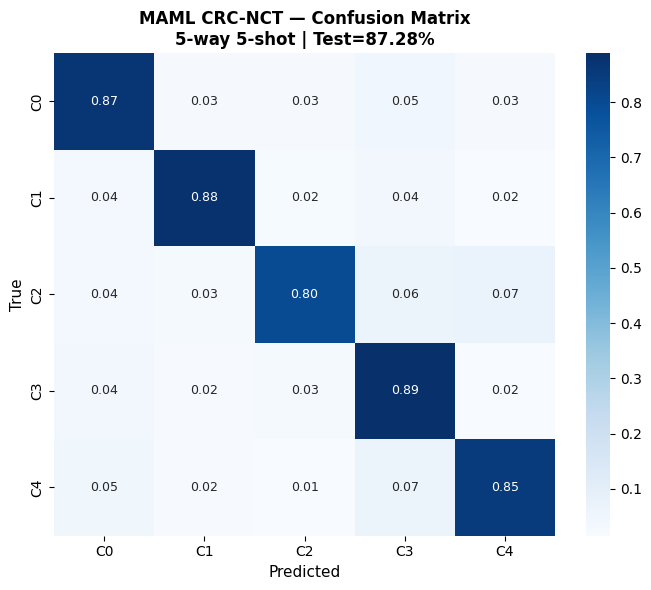

              precision    recall  f1-score   support

          C0       0.84      0.87      0.86      1000
          C1       0.90      0.88      0.89      1000
          C2       0.89      0.80      0.84      1000
          C3       0.80      0.89      0.84      1000
          C4       0.86      0.85      0.86      1000

    accuracy                           0.86      5000
   macro avg       0.86      0.86      0.86      5000
weighted avg       0.86      0.86      0.86      5000

Saved.


In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
ce = nn.CrossEntropyLoss()

for batch in test_dl:
    for (support, query, s_tgt, q_tgt) in batch:
        support = support.to(DEVICE)
        query   = query.to(DEVICE)
        s_tgt   = s_tgt.to(DEVICE)
        q_tgt   = q_tgt.to(DEVICE)

        inner_opt = torch.optim.SGD(
            model.parameters(), lr=INNER_LR)

        with higher.innerloop_ctx(
            model, inner_opt,
            copy_initial_weights=True,
            track_higher_grads=False,
        ) as (fmodel, diffopt):
            for _ in range(INNER_STEPS):
                inner_loss = ce(fmodel(support), s_tgt)
                diffopt.step(inner_loss)
            with torch.no_grad():
                q_logits = fmodel(query)
                preds    = q_logits.argmax(1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(q_tgt.cpu().numpy())

class_labels = [f'C{i}' for i in range(N_WAY)]

fig, ax = plt.subplots(figsize=(7, 6))
cm   = confusion_matrix(all_labels, all_preds)
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels, ax=ax,
            annot_kws={'size': 9})
ax.set_title(f'MAML CRC-NCT — Confusion Matrix\n'
             f'{N_WAY}-way {K_SHOT}-shot | '
             f'Test={test_acc:.2f}%',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('True', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
    'maml_confusion_matrix.png'), dpi=150)
plt.show()

print(classification_report(
    all_labels, all_preds,
    target_names=class_labels))
print('Saved.')